# DistilBERT Classification

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This file implements the DistilBERT model for classification.
#### Model Training Reference - https://huggingface.co/docs/transformers/en/tasks/sequence_classification

### Import the required libraries

In [27]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.utils import class_weight
from transformers import create_optimizer
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

### Load the dataset

In [28]:
# Read the CSV file
document_file_path = "../synthetic_dataset/document_classified_data.csv"
df = pd.read_csv(document_file_path)
df["processed_text"] = df["processed_text"].astype(str)

### Tokenization

In [29]:
# Tokenize the document data
tokenizer = AutoTokenizer.from_pretrained('distilbert/distilbert-base-uncased')

def preprocess_function(text):
    return tokenizer.encode(text, truncation=True, padding='max_length', max_length=256)

df["input_ids"] = df["processed_text"].apply(preprocess_function)

# Splitting the data
train_data, test_data = train_test_split(df, test_size=0.2, random_state=42, stratify=df["sensitive"])

### Model Creation

In [30]:
# Setting up the model details
batch_size = 32
num_epochs = 10
batches_per_epoch = len(train_data) // batch_size
total_train_steps = int(batches_per_epoch * num_epochs)
optimizer, schedule = create_optimizer(init_lr=2e-5, num_warmup_steps=0, num_train_steps=total_train_steps)

model = TFAutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    dropout=0.2,
    attention_dropout=0.2
)

# Compile the model
model.compile(optimizer=optimizer, loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

model.summary()

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFDistilBertForSequenceClassification: ['vocab_transform.bias', 'vocab_layer_norm.weight', 'vocab_projector.bias', 'vocab_layer_norm.bias', 'vocab_transform.weight']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFDistilBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['pre_classifier.weight', 'pre_classifier.bias', 'classifier.weight', 'classifier.bias']
You should 

Model: "tf_distil_bert_for_sequence_classification_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 distilbert (TFDistilBertMa  multiple                  66362880  
 inLayer)                                                        
                                                                 
 pre_classifier (Dense)      multiple                  590592    
                                                                 
 classifier (Dense)          multiple                  1538      
                                                                 
 dropout_259 (Dropout)       multiple                  0 (unused)
                                                                 
Total params: 66955010 (255.41 MB)
Trainable params: 66955010 (255.41 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Training and Evaluation

In [31]:
history = model.fit(
    x=train_data["input_ids"].to_list(),
    y=train_data["sensitive"].tolist(),
    validation_data=(test_data["input_ids"].to_list(), test_data["sensitive"].tolist()),
    batch_size=batch_size,
    epochs=num_epochs
)

y_pred_prob = model.predict(test_data["input_ids"].to_list())
y_pred = tf.argmax(y_pred_prob.logits, axis=1)

Epoch 1/10
30/30 [==============================] - 38s 435ms/step - loss: 0.6622 - accuracy: 0.6094 - val_loss: 0.6354 - val_accuracy: 0.6375
Epoch 2/10
30/30 [==============================] - 8s 282ms/step - loss: 0.5654 - accuracy: 0.7167 - val_loss: 0.4723 - val_accuracy: 0.7750
Epoch 3/10
30/30 [==============================] - 8s 283ms/step - loss: 0.4060 - accuracy: 0.8406 - val_loss: 0.4306 - val_accuracy: 0.8167
Epoch 4/10
30/30 [==============================] - 8s 283ms/step - loss: 0.3220 - accuracy: 0.8813 - val_loss: 0.4022 - val_accuracy: 0.8458
Epoch 5/10
30/30 [==============================] - 8s 283ms/step - loss: 0.2601 - accuracy: 0.9021 - val_loss: 0.3745 - val_accuracy: 0.8458
Epoch 6/10
30/30 [==============================] - 8s 283ms/step - loss: 0.2194 - accuracy: 0.9198 - val_loss: 0.3570 - val_accuracy: 0.8667
Epoch 7/10
30/30 [==============================] - 8s 283ms/step - loss: 0.1921 - accuracy: 0.9365 - val_loss: 0.4250 - val_accuracy: 0.8500
Epoch

In [32]:
accuracy = accuracy_score(test_data["sensitive"], y_pred)
f1 = f1_score(test_data["sensitive"], y_pred)
recall = recall_score(test_data["sensitive"], y_pred)
precision = precision_score(test_data["sensitive"], y_pred)

df_scores = pd.DataFrame(columns=["Metric", "Value"])
df_scores = df_scores._append({"Metric": "Accuracy", "Value":accuracy}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Precision", "Value":precision}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Recall", "Value":recall}, ignore_index=True)
df_scores = df_scores._append({"Metric": "F1 score:", "Value":f1}, ignore_index=True)

df_scores.head()

,Metric,Value
0,Accuracy,0.875000
1,Precision,0.871622
2,Recall,0.921429
3,F1 score:,0.895833


### Plotting the accuracy

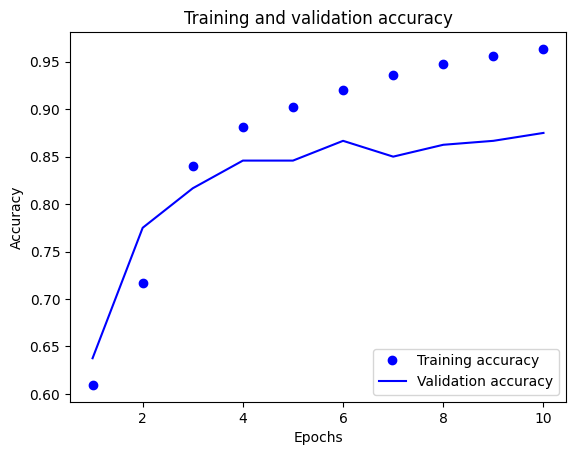

In [33]:
# Plotting the accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'bo', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()